In [1]:
import tensorflow as tf
tf.config.set_visible_devices([], 'GPU')

2026-11-17 20:30:39.587648: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-17 20:30:40.390642: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-17 20:30:43.417674: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1794934846.738351   12495 gpu_device.cc:2342] Cannot dlopen some GPU libraries.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

In [3]:
x_train = pd.read_csv('../data/processed/x_train_scaled.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')
x_val = pd.read_csv('../data/processed/x_val_scaled.csv')
y_val = pd.read_csv('../data/processed/y_val.csv')
x_test = pd.read_csv('../data/processed/x_test_scaled.csv')
y_test = pd.read_csv('../data/processed/y_test.csv')


In [4]:
x_train.shape, y_train.shape, x_val.shape, y_val.shape , x_test.shape, y_test.shape

((16138, 17), (16138, 1), (4493, 17), (4493, 1), (13096, 17), (13096, 1))

In [5]:
input = layers.Input(shape=(x_train.shape[1],))
x = layers.Dense(64)(input)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.2)(x)
output = layers.Dense(1)(x)
model = keras.Model(inputs=input, outputs=output)

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae' , 'mse'])

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath='../models/dense_model.h5',
        save_best_only=True,
        monitor='val_loss'
        )
    ]


In [8]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1718.2812 - mae: 29.9375 - mse: 1718.2812 - val_loss: 2540.2312 - val_mae: 35.7010 - val_mse: 2540.2312
Epoch 2/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1709.6608 - mae: 29.7225 - mse: 1709.6608 - val_loss: 2574.4341 - val_mae: 35.8727 - val_mse: 2574.4341
Epoch 3/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1725.0641 - mae: 29.8461 - mse: 1725.0641 - val_loss: 2565.5115 - val_mae: 35.8238 - val_mse: 2565.5115
Epoch 4/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1717.9677 - mae: 29.8145 - mse: 1717.9677 - val_loss: 2663.7429 - val_mae: 36.3372 - val_mse: 2663.7429
Epoch 5/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1716.4619 - mae: 29.8389 - mse: 1716.4619 - val_loss: 2538.4485 - val_mae: 35.6876 - val_mse: 2538.4485
Epoch 6/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1727.3809 - mae: 29.9528 - mse: 1727.3809 - val_loss: 2516.3740 - val_mae: 35.6521 - val_mse: 2516.3740
Epoch 7/10

505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1700.9225 - mae: 29.7136 - mse: 1700.9225 - val_loss: 2493.7939 - val_mae: 35.6344 - val_mse: 2493.7939
Epoch 34/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1719.8936 - mae: 29.8409 - mse: 1719.8936 - val_loss: 2612.5989 - val_mae: 35.9899 - val_mse: 2612.5989
Epoch 35/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1714.4664 - mae: 29.7718 - mse: 1714.4664 - val_loss: 2527.4182 - val_mae: 35.7095 - val_mse: 2527.4182
Epoch 36/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1715.2037 - mae: 29.8073 - mse: 1715.2037 - val_loss: 2520.9302 - val_mae: 35.6218 - val_mse: 2520.9302
Epoch 37/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1728.3795 - mae: 29.8969 - mse: 1728.3795 - val_loss: 2598.9021 - val_mae: 35.9092 - val_mse: 2598.9021
Epoch 38/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1707.1456 - mae: 29.6492 - mse: 1707.1456 - val_loss: 2650.5447 - val_mae: 36.2227 - val_mse: 2650.5447
Epoch 39/100
505/

In [9]:
history.history.keys()

dict_keys(['loss', 'mae', 'mse', 'val_loss', 'val_mae', 'val_mse'])

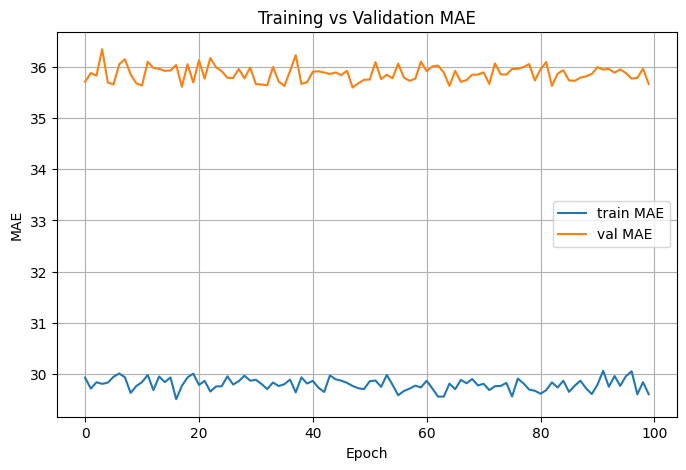

In [10]:
# elbow method
plt.figure(figsize=(8, 5))
plt.plot(history.history["mae"], label="train MAE")
plt.plot(history.history["val_mae"], label="val MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

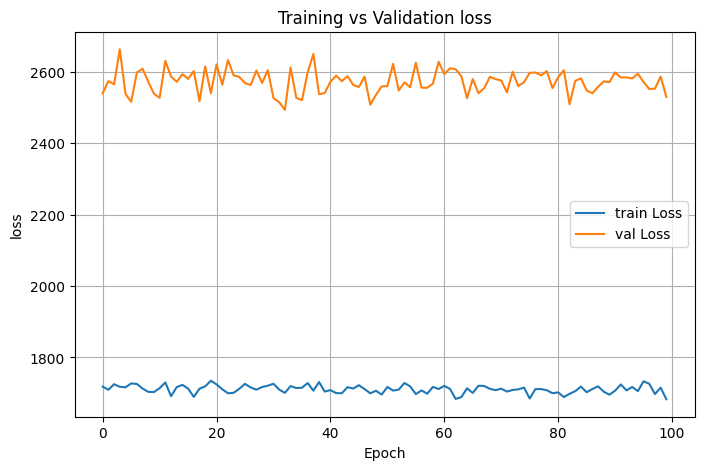

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="train Loss")
plt.plot(history.history["val_loss"], label="val Loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.title("Training vs Validation loss")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
model = keras.models.load_model("../models/dense_model.h5")

In [14]:
print("Mean Squared Error:", model.evaluate(x_test, y_test)[1])
print("R-squared:", 1 - model.evaluate(x_test, y_test)[0] / y_test.var())

410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6019.4604 - mean_absolute_error: 66.1059 - mean_squared_error: 6019.4604
Mean Squared Error: 66.10587310791016
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6019.4604 - mean_absolute_error: 66.1059 - mean_squared_error: 6019.4604
R-squared: RUL   -1.138257
dtype: float64
